In [3]:
import base64
import hashlib
import os
import shutil
import subprocess
import tempfile
import zipfile
import sys

import pandas as pd
import numpy as np
import networkx as nx

from rdkit import Chem
from rdkit.Chem import Crippen, Descriptors, Lipinski, rdMolDescriptors, AllChem, MACCSkeys
from pathlib import Path
from sklearn.model_selection import StratifiedKFold

In [4]:
import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem, Descriptors



def mw_diff(smiles): 
    
    smiles = np.array(smiles)

    all_mols = []

    for smile_id, smile in enumerate(smiles): 
        mol = Chem.MolFromSmiles(smile)
        all_mols.append(mol)


    mw_diff_lst = []
    for mol_id in range(len(all_mols)): 
        for mol_id_second_mol in range(len(all_mols)): 
            mw_diff = Descriptors.MolWt(all_mols[mol_id])-Descriptors.MolWt(all_mols[mol_id_second_mol])
            mw_diff_lst.append(mw_diff)

    
    return mw_diff_lst


def structural_similarity(smiles):

    smiles = np.array(smiles)

    all_mols = []

    for smile_id, smile in enumerate(smiles): 
        # print(smile_id)
        mol = Chem.MolFromSmiles(smile)
        all_mols.append(mol)


    # generate fingerprints 
    fpgen = AllChem.GetRDKitFPGenerator()

    fps = []
    
    for mol_id, x in enumerate(all_mols):
        try: 
            fps.append(fpgen.GetFingerprint(x))
        except: 
            print('invalid:', mol_id)


    sim_vals = []

    for fp_id in range(len(fps)): 
        for fp_id_second_mol in range(len(fps)): 
            sim_vals.append(DataStructs.TanimotoSimilarity(fps[fp_id],fps[fp_id_second_mol]))
            
    return sim_vals, fps, all_mols


In [5]:
# output file names: 

#B3DB
# ds = "b3db" # or,
ds = "b3db" 
required_input_df = f"../datasets/01_B3DB_classification.csv"
corrected_b3db = f"../datasets/preprocessed_{ds}/corrected_{ds}.csv"
druglike_b3db_file = f'../datasets/preprocessed_{ds}/druglike_{ds}.csv'
OPEN_CHEM_LIB_JAR = "../tools/datawarrior_all.jar"
OUTPUT_SDF = Path(f'../datasets/preprocessed_{ds}/druglike_{ds}_seeded_3d.sdf')
data_warrior_3D_file = OUTPUT_SDF
druglike_labelled_ds=f'../datasets/preprocessed_{ds}/druglike_{ds}_labelled.csv'
full_dataset_path = druglike_labelled_ds
outerfold_csv_path = Path(f"../datasets/druglike_{ds}_labelled_outerfolds.csv")

BASE_SEED = 20260915
DIELECTRIC_CONSTANT = 1

In [6]:
# Remove all metals
df = pd.read_csv(required_input_df).rename(columns={"compound_name": "Name"})

df["Class"] = df["BBB+/BBB-"].map({"BBB+": 0, "BBB-": 1})
df = df[["NO.", "Name", "SMILES", "logBB", "Class"]]

# correct incorrect structures
incorrect = df["NO."].isin([5044, 7738])
df.loc[incorrect, "SMILES"] = df.loc[incorrect, "SMILES"].str.replace("[C+](", "C(", regex=False)

df.to_csv(corrected_b3db, index=False)


In [7]:
# Import the removed metals dataset – removed manually:

df = pd.read_csv(corrected_b3db)

mols = df["SMILES"].map(Chem.MolFromSmiles)

full_dataset = df
smiles = full_dataset['SMILES']

# Check validity by generating fp using rdkit.
invalid = []
fpgen = AllChem.GetRDKitFPGenerator()
for smile_id, smile in enumerate(smiles): 
    try: 
        mol = Chem.MolFromSmiles(smile)
        fpgen.GetFingerprint(mol)
    except: 
        invalid.append(smile_id)

# Remove invalid structures. 
all_valid_dataset = full_dataset.drop(index=invalid).reset_index(drop=True)
smiles_valid = all_valid_dataset['SMILES']
# logBB_valid = all_valid_dataset['logBB']
# bbb_class_valid = all_valid_dataset['Class']

print('Dataset size after removing unstandardizable smiles structures: ', len(all_valid_dataset))

# Calculate structural similarity and MW to identify stereoisomers.
sim_vals, _, _ = structural_similarity(smiles_valid)
sim_matrix_valid = np.array(sim_vals).reshape((len(smiles_valid), len(smiles_valid)))
mw_diff_matrix = np.array(mw_diff(smiles_valid)).reshape((len(smiles_valid), len(smiles_valid)))

sim_inds, mw_inds= np.column_stack(np.where(sim_matrix_valid == 1)),  np.column_stack(np.where(mw_diff_matrix == 0))
sim_inds, mw_inds = np.array([np.array([x[0], x[1]]) for x in sim_inds if x[0]<x[1]]), np.array([np.array([x[0], x[1]]) for x in mw_inds if x[0]<x[1]])
# drop_inds = [ list(el) for el in sim_inds if el in mw_inds]

mw_pairs = {tuple(pair) for pair in mw_inds}
drop_inds = [list(pair) for pair in sim_inds if tuple(pair) in mw_pairs]

# Find clusters of stereoisomers and select the one with the lowest index (most likely to have a logBB value)
G = nx.Graph()
G.add_edges_from(drop_inds)
clusters = list(nx.connected_components(G))
drop_ind_clusters = [sorted(list(c))[1:] for c in clusters]
drop_ind_clusters_flat = [item for sublist in drop_ind_clusters for item in sublist]

# Remove all redundant stereoisomers



all_valid_dataset_no_str = all_valid_dataset.drop(index=drop_ind_clusters_flat).reset_index(drop=True)

Dataset size after removing unstandardizable smiles structures:  7807


In [8]:
print(len(all_valid_dataset_no_str))

4094


In [9]:
def is_organic_molecule(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return mol is not None and mol.GetNumHeavyAtoms() >= 2 and len(Chem.GetMolFrags(mol)) == 1 and any(atom.GetAtomicNum() == 6 for atom in mol.GetAtoms())

organic_mask = all_valid_dataset_no_str["SMILES"].map(is_organic_molecule)
removed_nonorganic = all_valid_dataset_no_str.loc[~organic_mask].copy()
all_valid_dataset_no_str = all_valid_dataset_no_str.loc[organic_mask].reset_index(drop=True)

print(f"Removed {len(removed_nonorganic)} non-organic/single-atom compounds")
display(removed_nonorganic[["NO.", "Name", "SMILES", "Class", "logBB"]])

# generate the drug like dataset

valid_unique_mols = all_valid_dataset_no_str["SMILES"].map(Chem.MolFromSmiles)

# annotate the dataset
all_valid_dataset_no_str[["MW", "nHBAcc", "nHBDon", "SLogP", "TopoPSA"]] = [
    [Descriptors.ExactMolWt(m), Lipinski.NumHAcceptors(m), Lipinski.NumHDonors(m), Crippen.MolLogP(m), rdMolDescriptors.CalcTPSA(m)]
    for m in valid_unique_mols
]


all_valid_dataset_no_str[["MW", "SLogP", "TopoPSA"]] = all_valid_dataset_no_str[["MW", "SLogP", "TopoPSA"]].round(2)
all_valid_dataset_no_str[["nHBAcc", "nHBDon"]] = all_valid_dataset_no_str[["nHBAcc", "nHBDon"]].astype(int)


base = all_valid_dataset_no_str

drug_like_mask = (
    base["MW"].le(800)
    & base["nHBDon"].le(6)
    & base["nHBAcc"].le(11)
    & base["SLogP"].le(5)
    & base["SLogP"].gt(0)
    & base["TopoPSA"].lt(180)
)

if ds == "b3db_bRo5": 
    drug_like_mask = (
        base["MW"].le(1000)
        & base["nHBDon"].le(6)
        & base["nHBAcc"].le(15)
        & base["SLogP"].le(10)
        & base["SLogP"].gt(-2)
        & base["TopoPSA"].lt(250)
    )


all_valid_dataset_drug_like = base.loc[drug_like_mask].copy()
all_valid_dataset_not_drug_like = base.loc[~drug_like_mask].copy()

all_valid_dataset_drug_like.to_csv(druglike_b3db_file,index=False,)

print("Cleaned valid dataset:", len(base))
print("Drug-like subset:", len(all_valid_dataset_drug_like))
print("Exact complement:", len(all_valid_dataset_not_drug_like))


Removed 23 non-organic/single-atom compounds


,NO.,Name,SMILES,Class,logBB
316,358,7439-93-2,[Li],0,-0.30
384,437,7439-90-9,[Kr],0,-0.16
462,521,water,O,0,-0.04
485,545,methane,C,0,0.00
507,569,nitrogen,N#N,0,0.03
508,570,argon,[Ar],0,0.03
509,571,nitrous oxide,[N-]=[N+]=O,0,0.03
511,573,"nitrous oxide, 99%",N#[N+]O,0,0.03
512,574,nitrogen,NN,0,0.03
513,575,7440-63-3,[Xe],0,0.03


Cleaned valid dataset: 4071
Drug-like subset: 3188
Exact complement: 883


In [10]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch


def plot_feature_distributions(
    df,
    features,
    class_col="bbb_class",
    nonpenetrant_value=1,
    penetrant_value=0,
    bins_by_feature=None,
    ncols=3,
    figsize_per_panel=(5.5, 4.2),
    save_path=None,
):
    """
    Plot overlapping feature histograms for BBB non-penetrant and penetrant
    molecules.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing the features and class labels.

    features : list[str]
        Features to plot.

    class_col : str
        Name of the binary class column.

    nonpenetrant_value
        Value corresponding to BBB non-penetrant molecules.

    penetrant_value
        Value corresponding to BBB penetrant molecules.

    bins_by_feature : dict, optional
        Dictionary specifying bins for individual features.

        Example:
            {
                "nHBDon": np.arange(-0.5, 7.5, 1),
                "MW": np.arange(0, 825, 10),
            }

    ncols : int
        Number of columns in the figure.

    save_path : str, optional
        File path for saving the figure.
    """

    bins_by_feature = bins_by_feature or {}

    # Include an extra axis for the legend.
    n_panels = len(features) + 1
    nrows = math.ceil(n_panels / ncols)

    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(
            figsize_per_panel[0] * ncols,
            figsize_per_panel[1] * nrows,
        ),
    )

    axes = np.asarray(axes).reshape(-1)

    nonpenetrant = df.loc[
        df[class_col] == nonpenetrant_value
    ]

    penetrant = df.loc[
        df[class_col] == penetrant_value
    ]

    for ax, feature in zip(axes, features):

        all_values = pd.to_numeric(
            df[feature],
            errors="coerce",
        ).dropna()

        np_values = pd.to_numeric(
            nonpenetrant[feature],
            errors="coerce",
        ).dropna()

        p_values = pd.to_numeric(
            penetrant[feature],
            errors="coerce",
        ).dropna()

        if feature in bins_by_feature:
            bins = bins_by_feature[feature]

        else:
            # Use integer-centered bins for low-cardinality integer features.
            is_integer_like = np.allclose(
                all_values,
                np.round(all_values),
            )

            if is_integer_like and all_values.nunique() <= 20:
                lower = int(np.floor(all_values.min()))
                upper = int(np.ceil(all_values.max()))

                bins = np.arange(
                    lower - 0.5,
                    upper + 1.5,
                    1,
                )

            else:
                bins = 35

        # Plot non-penetrant first so penetrant bars are overlaid.
        ax.hist(
            p_values,
            bins=bins,
            color="#009E2F",
            edgecolor="black",
            linewidth=1,
            alpha=0.95,
            label="BBB Penetrant",
        )

        ax.hist(
            np_values,
            bins=bins,
            color="skyblue",
            edgecolor="black",
            linewidth=1,
            alpha=0.85,
            label="BBB Non-Penetrant",
        )

      
        ax.set_xlabel(feature)
        ax.set_ylabel("Count")

    # Put the legend in the next available panel.
    legend_ax = axes[len(features)]
    legend_ax.axis("off")

    legend_handles = [
        Patch(
            facecolor="skyblue",
            edgecolor="black",
            label="BBB Non-Penetrant",
        ),
        Patch(
            facecolor="#009E2F",
            edgecolor="black",
            label="BBB Penetrant",
        ),
    ]

    legend_ax.legend(
        handles=legend_handles,
        loc="center",
        frameon=True,
        fontsize=18,
    )

    # Remove any remaining empty panels.
    for ax in axes[len(features) + 1:]:
        ax.axis("off")

    plt.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=1200,
            bbox_inches="tight",
        )

    plt.show()

    return fig, axes

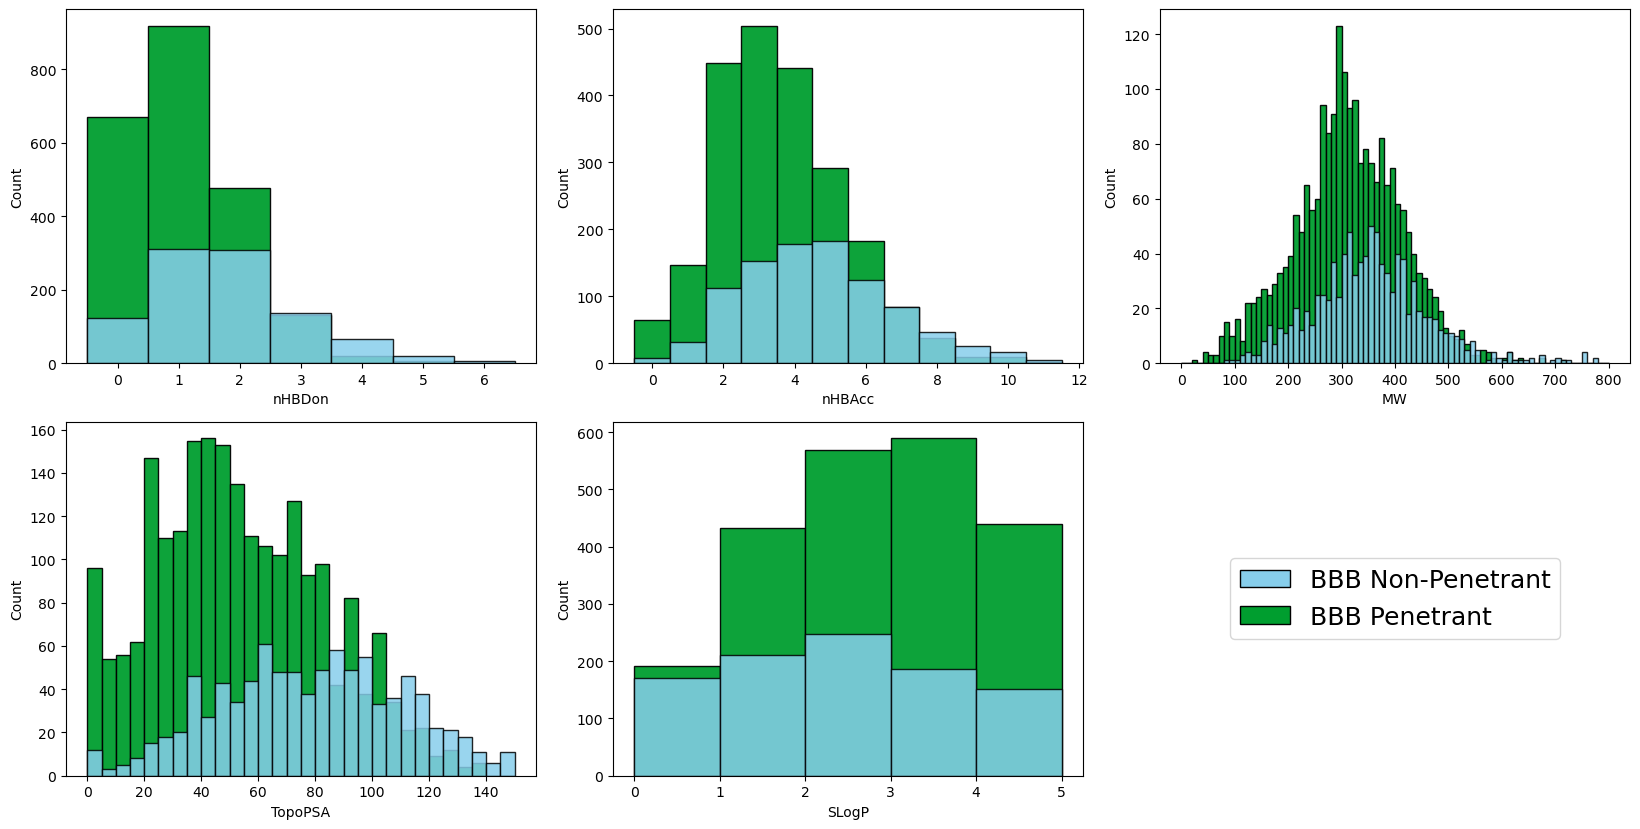

(<Figure size 1650x840 with 6 Axes>,
 array([<Axes: xlabel='nHBDon', ylabel='Count'>,
        <Axes: xlabel='nHBAcc', ylabel='Count'>,
        <Axes: xlabel='MW', ylabel='Count'>,
        <Axes: xlabel='TopoPSA', ylabel='Count'>,
        <Axes: xlabel='SLogP', ylabel='Count'>, <Axes: >], dtype=object))

In [11]:
features = [
    "nHBDon",
    "nHBAcc",
    "MW",
    "TopoPSA",
    "SLogP",
]

bins_by_feature = {
    "nHBDon": np.arange(-0.5, 7.5, 1),
    "nHBAcc": np.arange(-0.5, 12.5, 1),
    "MW": np.arange(0, 810, 10),
    "TopoPSA": np.arange(0, 155, 5),
    "SLogP": np.arange(0, 6, 1),
}

plot_feature_distributions(
    df=all_valid_dataset_drug_like,
    features=features,
    class_col="Class",
    nonpenetrant_value=1,
    penetrant_value=0,
    bins_by_feature=bins_by_feature,
    ncols=3,
    save_path="./figures/figure_s16.png",
)

##### Generate OpenChemLib 3D conformers


In [12]:
# Use the jar from the SAME DataWarrior version used for the manuscript.
# Leave as None to search the macOS app and launcher-managed update folder.
# Typical macOS path: /Applications/DataWarrior.app/Contents/Java/update/datawarrior_all.jar


def find_openchemlib_jar(explicit_path=None):
    # DataWarrior may package OpenChemLib in openchemlib.jar OR in a larger
    # DataWarrior jar. Test jar contents instead of relying on the filename.
    required_classes = {
        'org/openmolecules/chem/conf/gen/ConformerGenerator.class',
        'com/actelion/research/chem/forcefield/mmff/ForceFieldMMFF94.class',
    }

    def contains_required_classes(path):
        try:
            with zipfile.ZipFile(path) as jar:
                names = set(jar.namelist())
            return required_classes.issubset(names)
        except (OSError, zipfile.BadZipFile):
            return False

    candidates = []
    if explicit_path:
        explicit_path = Path(explicit_path).expanduser()
        if not explicit_path.is_file():
            raise FileNotFoundError(f'OPEN_CHEM_LIB_JAR does not exist: {explicit_path}')
        if not contains_required_classes(explicit_path):
            raise ValueError(f'The selected jar does not contain the required OpenChemLib classes: {explicit_path}')
        return explicit_path.resolve()
    if os.environ.get('OPENCHEMLIB_JAR'):
        candidates.append(Path(os.environ['OPENCHEMLIB_JAR']).expanduser())


    # Spotlight fallback catches launcher-managed jars stored in an unexpected
    # macOS user directory without recursively scanning the entire home folder.
    mdfind = shutil.which('mdfind')
    if mdfind:
        query = "kMDItemFSName == '*openchemlib*.jar'cd || kMDItemFSName == '*datawarrior*.jar'cd"
        result = subprocess.run([mdfind, query], capture_output=True, text=True, check=False)
        candidates.extend(Path(line) for line in result.stdout.splitlines() if line.strip())

    # Prefer a jar explicitly named for OpenChemLib if more than one valid jar exists.
    candidates = sorted(set(candidates), key=lambda p: ('openchemlib' not in p.name.lower(), str(p)))
    for candidate in candidates:
        if candidate.is_file() and contains_required_classes(candidate):
            return candidate.resolve()
    raise FileNotFoundError(
        'No installed jar containing the required OpenChemLib conformer classes was found. '
        'The usual macOS target is /Applications/DataWarrior.app/Contents/Java/update/datawarrior_all.jar. '
        'In Terminal, run: find /Applications/DataWarrior.app ~/Library -type f -name \"*.jar\" 2>/dev/null '
        'Then set OPEN_CHEM_LIB_JAR to the matching DataWarrior/OpenChemLib jar path.'
    )

def conformer_seed(smiles, base_seed=BASE_SEED):
    digest = hashlib.sha256(f'{base_seed}\0{smiles}'.encode()).digest()[:8]
    seed = int.from_bytes(digest, 'big', signed=True)
    return seed if seed != 0 else 1

def b64(value):
    return base64.b64encode(str(value).encode('utf-8')).decode('ascii')

def find_java_runtime(ocl_jar):
    # Prefer the Java runtime bundled with the selected DataWarrior app.
    # /usr/bin/java on macOS may be only a placeholder that prints
    # 'Unable to locate a Java Runtime' and exits.
    ocl_jar = Path(ocl_jar).resolve()
    candidates = []
    app_bundle = next((parent for parent in ocl_jar.parents if parent.suffix == '.app'), None)
    if app_bundle is not None:
        contents = app_bundle / 'Contents'
        candidates.extend(
            path for path in contents.rglob('java')
            if path.is_file() and path.parent.name == 'bin'
        )

    system_java = shutil.which('java')
    if system_java:
        candidates.append(Path(system_java))

    diagnostics = []
    for candidate in dict.fromkeys(candidates):
        if not os.access(candidate, os.X_OK):
            continue
        version = subprocess.run(
            [str(candidate), '-version'], capture_output=True, text=True, check=False
        )
        if version.returncode != 0:
            diagnostics.append(f'{candidate}: {version.stderr.strip()}')
            continue
        modules = subprocess.run(
            [str(candidate), '--list-modules'], capture_output=True, text=True, check=False
        )
        if modules.returncode == 0 and 'jdk.compiler@' in modules.stdout:
            return candidate.resolve()
        diagnostics.append(f'{candidate}: Java found, but the jdk.compiler module is absent')

    detail = '\n'.join(diagnostics) if diagnostics else 'No Java executable was found.'
    raise RuntimeError(
        'A working Java runtime with the jdk.compiler module is required. '
        'The notebook checked DataWarrior’s bundled runtime before the system Java.\n' + detail
    )

def pack_sdf_properties(row):
    """Encode every original CSV column/value for the Java helper."""
    return "\u001e".join(
        f"{column}\u001f{row[column]}"
        for column in row.index
    )

In [13]:
JAVA_SOURCE = r'''
import com.actelion.research.chem.MolfileV3Creator;
import com.actelion.research.chem.StereoMolecule;
import com.actelion.research.chem.SmilesParser;
import com.actelion.research.chem.forcefield.mmff.ForceFieldMMFF94;
import org.openmolecules.chem.conf.gen.ConformerGenerator;
import org.openmolecules.chem.conf.gen.RigidFragmentCache;
import java.io.*;
import java.nio.charset.StandardCharsets;
import java.nio.file.*;
import java.util.*;

public class SeededDataWarriorConformers {
  static final int MAX_TORSION_SETS = 1000;
  static final int MAX_ITERATIONS = 10000;
  static final double GRADIENT_TOLERANCE = 0.0001;
  static final double FUNCTION_TOLERANCE = 1.0e-6;

  public static void main(String[] args) throws Exception {
    Path manifest = Path.of(args[0]);
    Path output = Path.of(args[1]);
    Path failures = Path.of(args[2]);
    double dielectric = Double.parseDouble(args[3]);
    RigidFragmentCache.getDefaultInstance().loadDefaultCache();
    ForceFieldMMFF94.initialize(ForceFieldMMFF94.MMFF94SPLUS);
    Map<String,Object> options = new HashMap<>();
    options.put("dielectric constant", dielectric);
    int inputCount = 0, writtenCount = 0, failureCount = 0;

    try (BufferedReader in = Files.newBufferedReader(manifest, StandardCharsets.UTF_8);
         BufferedWriter sdf = Files.newBufferedWriter(output, StandardCharsets.UTF_8);
         BufferedWriter failed = Files.newBufferedWriter(failures, StandardCharsets.UTF_8)) {
      failed.write("dataframe_row\tinput_id\tsmiles\terror\n");
      String line;
      while ((line = in.readLine()) != null) {
        inputCount++;
        String[] f = line.split("\\t", -1);
        String row = decode(f[0]), id = decode(f[1]), smiles = decode(f[2]);
        long seed = Long.parseLong(f[3]);
        String originalProperties = decode(f[4]);
        try {
          StereoMolecule mol = new StereoMolecule();
          new SmilesParser().parse(mol, smiles);
          ConformerGenerator cg = new ConformerGenerator(seed, true);
          if (!cg.initializeConformers(mol, ConformerGenerator.STRATEGY_LIKELY_SYSTEMATIC,
                  MAX_TORSION_SETS, false))
            throw new Exception("Conformer generator could not initialize");
          mol = cg.getNextConformerAsMolecule(mol);
          if (mol == null) throw new Exception("No conformer generated");
          double energy = Double.NaN;
          String minimizationError = "";

          try {
            energy = minimize(mol, options);
          } catch (Exception e) {
            // Match DataWarrior: retain the generated conformer when
            // MMFF94 typing or minimization fails.
            minimizationError = e.getClass().getSimpleName() + ": " + e.getMessage();
          }

          center(mol);
          mol.setName(id.isBlank() ? "row " + row : id);
          sdf.write(new MolfileV3Creator(mol).getMolfile());
          // Restore every original CSV column using its exact original name.
          for (String entry : originalProperties.split("\u001e", -1)) {
            if (entry.isEmpty()) continue;

            int separator = entry.indexOf('\u001f');
            if (separator < 0) continue;

            String columnName = entry.substring(0, separator);
            String columnValue = entry.substring(separator + 1);

            property(sdf, columnName, columnValue);
          }
          property(sdf, "DATAFRAME_ROW", row);
          property(sdf, "INPUT_ID", id);
          property(sdf, "INPUT_SMILES", smiles);
          property(sdf, "CONFORMER_SEED", Long.toString(seed));
          property(sdf, "CONFORMER_ALGORITHM", "systematic, low-energy biased");
          property(sdf, "TORSION_SOURCE", "crystallographic");
          property(sdf, "FORCE_FIELD", "MMFF94s+");
          property(sdf, "DIELECTRIC_CONSTANT", Double.toString(dielectric));
          property(
              sdf,
              "MMFF94_ENERGY",
              Double.isNaN(energy) ? "" : String.format(Locale.ROOT, "%.9g", energy)
          );
          property(sdf, "MINIMIZATION_ERROR", minimizationError);
          sdf.write("$$$$\n");
          writtenCount++;
        } catch (Throwable e) {
          failureCount++;
          failed.write(clean(row)+"\t"+clean(id)+"\t"+clean(smiles)+"\t"
              +clean(e.getClass().getSimpleName()+": "+e.getMessage())+"\n");
        }
      }
    }
    System.out.printf(Locale.ROOT, "Input: %d  Written: %d  Failed: %d%n",
        inputCount, writtenCount, failureCount);
    if (failureCount != 0) System.exit(1);
  }

  static double minimize(StereoMolecule mol, Map<String,Object> options) throws Exception {
    int[] fragmentNo = new int[mol.getAllAtoms()];
    int fragmentCount = mol.getFragmentNumbers(fragmentNo, false, true);
    double energy = Double.NaN;
    if (fragmentCount == 1) {
      ForceFieldMMFF94 ff = new ForceFieldMMFF94(mol, ForceFieldMMFF94.MMFF94SPLUS, options);
      int error = ff.minimise(MAX_ITERATIONS, GRADIENT_TOLERANCE, FUNCTION_TOLERANCE);
      if (error != 0) throw new Exception("MMFF94 error code " + error);
      energy = ff.getTotalEnergy();
    } else {
      StereoMolecule[] fragments = mol.getFragments(fragmentNo, fragmentCount);
      int maxAtoms = 0;
      for (StereoMolecule fragment : fragments) {
        if (fragment.getAllAtoms() > 2) {
          ForceFieldMMFF94 ff = new ForceFieldMMFF94(fragment, ForceFieldMMFF94.MMFF94SPLUS, options);
          int error = ff.minimise(MAX_ITERATIONS, GRADIENT_TOLERANCE, FUNCTION_TOLERANCE);
          if (error != 0) throw new Exception("MMFF94 error code " + error);
          if (maxAtoms < fragment.getAllAtoms()) {
            maxAtoms = fragment.getAllAtoms(); energy = ff.getTotalEnergy();
          }
        }
      }
      int[] atomInFragment = new int[fragmentCount];
      for (int atom=0; atom<fragmentNo.length; atom++) {
        int fragment = fragmentNo[atom], sourceAtom = atomInFragment[fragment]++;
        mol.setAtomX(atom, fragments[fragment].getAtomX(sourceAtom));
        mol.setAtomY(atom, fragments[fragment].getAtomY(sourceAtom));
        mol.setAtomZ(atom, fragments[fragment].getAtomZ(sourceAtom));
      }
    }
    return energy;
  }

  static void center(StereoMolecule mol) {
    double x=0, y=0, z=0;
    for (int a=0; a<mol.getAllAtoms(); a++) { x+=mol.getAtomX(a); y+=mol.getAtomY(a); z+=mol.getAtomZ(a); }
    x/=mol.getAllAtoms(); y/=mol.getAllAtoms(); z/=mol.getAllAtoms();
    for (int a=0; a<mol.getAllAtoms(); a++) {
      mol.setAtomX(a,mol.getAtomX(a)-x); mol.setAtomY(a,mol.getAtomY(a)-y); mol.setAtomZ(a,mol.getAtomZ(a)-z);
    }
  }

  static void property(BufferedWriter w, String name, String value) throws Exception {
    w.write(">  <"+name+">\n"+clean(value)+"\n\n");
  }
  static String decode(String s) { return new String(Base64.getDecoder().decode(s), StandardCharsets.UTF_8); }
  static String clean(String s) { return s == null ? "" : s.replace('\t',' ').replace('\r',' ').replace('\n',' '); }
}
'''

print('Seeded OpenChemLib helper defined.')

Seeded OpenChemLib helper defined.


In [14]:
# Generate one reproducible 3D conformer for every row in the drug-like dataset.
ocl_jar = find_openchemlib_jar(OPEN_CHEM_LIB_JAR)

java_candidates = [
    path for path in Path(sys.prefix).rglob("java")
    if path.is_file() and path.parent.name == "bin"
]

if not java_candidates:
    raise FileNotFoundError(
        f"Java was not installed under the active environment: {sys.prefix}"
    )

java = java_candidates[0]
print("Using Java:", java)


OUTPUT_SDF = OUTPUT_SDF.resolve()
OUTPUT_SDF.parent.mkdir(parents=True, exist_ok=True)
failures_file = OUTPUT_SDF.with_suffix(OUTPUT_SDF.suffix + '.failures.tsv')

# NO. is the stable B3DB identifier; the DataFrame index is also retained explicitly.
# Read as strings so every value and column name is preserved as written
sdf_source_df = pd.read_csv(
    druglike_b3db_file,
    dtype=str,
    keep_default_na=False,
)

id_column = "NO." if "NO." in sdf_source_df.columns else None

with tempfile.TemporaryDirectory(prefix="seeded_openchemlib_") as tmp:
    tmp = Path(tmp)
    java_file = tmp / "SeededDataWarriorConformers.java"
    manifest = tmp / "manifest.tsv"
    java_file.write_text(JAVA_SOURCE, encoding="utf-8")

    with manifest.open("w", encoding="utf-8", newline="") as handle:
        for dataframe_row, row in sdf_source_df.iterrows():
            smiles = row["SMILES"].strip()
            input_id = row[id_column] if id_column else dataframe_row
            seed = conformer_seed(smiles)
            properties = pack_sdf_properties(row)

            handle.write(
                f"{b64(dataframe_row)}\t"
                f"{b64(input_id)}\t"
                f"{b64(smiles)}\t"
                f"{seed}\t"
                f"{b64(properties)}\n"
            )

    command = [
        java, '--class-path', str(ocl_jar), str(java_file),
        str(manifest), str(OUTPUT_SDF), str(failures_file), str(DIELECTRIC_CONSTANT),
    ]
    print('Using OpenChemLib:', ocl_jar)
    print('Using Java:', java)
    print('Base seed:', BASE_SEED)
    result = subprocess.run(command, capture_output=True, text=True, check=False)
    if result.stdout.strip():
        print(result.stdout.strip())

if result.returncode != 0:
    error_detail = result.stderr.strip() or 'Java exited without an error message.'
    if failures_file.exists() and failures_file.stat().st_size > 0:
        error_detail += f'\nPer-molecule failures, if any: {failures_file}'
    raise RuntimeError(f'Conformer generation failed:\n{error_detail}')

# Verify the critical one-input-row/one-SDF-record relationship.
with OUTPUT_SDF.open('r', encoding='utf-8') as handle:
    sdf_record_count = sum(line.rstrip() == '$$$$' for line in handle)
assert sdf_record_count == len(all_valid_dataset_drug_like), (
    f'SDF has {sdf_record_count} records but the input has {len(all_valid_dataset_drug_like)} rows.'
)
if failures_file.exists() and failures_file.read_text(encoding='utf-8').count('\n') <= 1:
    failures_file.unlink()
print(f'Wrote {sdf_record_count} reproducible V3000 records to {OUTPUT_SDF}')

Using Java: /Users/sziadat/miniforge3/envs/bbbx_env_revisions/lib/jvm/bin/java
Using OpenChemLib: /Users/sziadat/Documents/bbbx/bbb-exc-score/tools/datawarrior_all.jar
Using Java: /Users/sziadat/miniforge3/envs/bbbx_env_revisions/lib/jvm/bin/java
Base seed: 20260915
Input: 3188  Written: 3188  Failed: 0
Wrote 3188 reproducible V3000 records to /Users/sziadat/Documents/bbbx/bbb-exc-score/datasets/preprocessed_b3db/druglike_b3db_seeded_3d.sdf


In [15]:
from rdkit.Chem.PandasTools import LoadSDF
from rdkit import RDLogger

RDLogger.DisableLog('rdApp.warning')   

# Load the unlabelled dataset
df = LoadSDF(data_warrior_3D_file, smilesName='SMILES')
df["SMILES"] = df["INPUT_SMILES"]
SMILES = df["SMILES"].copy()

supervised_label_df = df[["NO.", "SMILES", "Class", "logBB"]].copy()
#supervised_label_df = df[['SMILES', 'Class', 'logBB']] #'logBB', 


In [16]:
RDLogger.DisableLog('rdApp.warning')   

# ECFP
fpgen = AllChem.GetMorganGenerator(radius=2)
ecfp_fingerprints = []
for smile in SMILES:
    mol = Chem.MolFromSmiles(smile)
    fp = Chem.rdMolDescriptors.GetMorganFingerprintAsBitVect(mol, 2).ToBitString()
    ecfp_fingerprints.append(list(fp))

ecfp_col_names = [f"ECFP_{i}" for i in range(0,2048)]
ecfp_df = pd.DataFrame(ecfp_fingerprints, columns=ecfp_col_names)

# Mordred
mordred_output_file = f"../datasets/preprocessed_{ds}/{ds}_drug_like_3d_mordred_labels.csv"

! python -m mordred -3 {data_warrior_3D_file} -o {mordred_output_file}
mordred_df = pd.read_csv(mordred_output_file)


# MACCS
def get_maccs_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol:
        return list(MACCSkeys.GenMACCSKeys(mol).ToList())

col_names = [f"MACCS_{i}" for i in range(0,167)]
maccs_fps = []
for smile in SMILES: 
    maccs_fps.append(get_maccs_fingerprint(smile))

maccs_fp_df = pd.DataFrame(data=maccs_fps, columns=col_names)


assert len(mordred_df) == len(df)
assert (mordred_df["name"].astype(str).reset_index(drop=True) == df["INPUT_ID"].astype(str).reset_index(drop=True)).all()

# Save dataset:
all_labelled_df = pd.concat([supervised_label_df, ecfp_df, mordred_df.iloc[:, 1:], maccs_fp_df], axis=1)
all_labelled_df.to_csv(druglike_labelled_ds,index=False)


[17:44:48] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[17:44:48] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[17:44:48] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[17:44:48] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[17:44:48] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[17:44:48] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[17:44:48] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[17:44:48] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[17:44:48] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol

In [17]:
# Save pre-filter descriptor names for Table S7.
from pathlib import Path
import pandas as pd

s7_source = Path(full_dataset_path)
s7_header = pd.read_csv(s7_source, nrows=0).columns

# Exclude identifiers and targets from descriptor counts.
s7_metadata = {"NO.", "SMILES", "Class", "logBB"}
if not s7_metadata.issubset(s7_header):
    raise ValueError(
        "Use the original labelled descriptor CSV, before feature filtering."
    )

s7_features = [name for name in s7_header if name not in s7_metadata]
s7_feature_file = s7_source.with_name(
    f"{s7_source.stem}_features_before_filtering.csv"
)

pd.DataFrame({"feature": s7_features}).to_csv(
    s7_feature_file, index=False
)
print(f"Saved {len(s7_features)} pre-filter features:")
print(s7_feature_file.resolve())

Saved 4041 pre-filter features:
/Users/sziadat/Documents/bbbx/bbb-exc-score/datasets/preprocessed_b3db/druglike_b3db_labelled_features_before_filtering.csv


In [ ]:
# Import Dataset
full_df = pd.read_csv(full_dataset_path)

smiles = full_df.loc[:, 'SMILES']
bbb_class = full_df.loc[:, 'Class']
logbb = full_df.loc[:, 'logBB']

starting_col = list(full_df.columns).index('Class') + 1
X_full = full_df.iloc[:, starting_col:]

bbb_class = np.array(bbb_class)
logbb = np.array(logbb)
col_names = list(full_df.columns)[starting_col:]

X_full = X_full.values
X_to_drop = pd.DataFrame(data=X_full, columns=col_names)
X_full_no_nan = X_to_drop.dropna(axis=1)
X_full_no_nan = X_full_no_nan.loc[:, X_full_no_nan.std() != 0]

X_all = X_full_no_nan.values

In [ ]:
mask = (np.isfinite(logbb) & np.isfinite(bbb_class))

threshold_class = (logbb[mask] < -1.0).astype(int)
observed_class = (bbb_class[mask].astype(int))
print(pd.crosstab(observed_class, threshold_class, rownames=["Recorded BBB class"], colnames=["Class implied by logBB"],))

agreement = np.mean( observed_class == threshold_class)
print(f"Agreement: {agreement:.3f}")
print(f"Disagreement: {1 - agreement:.3f}")

Class implied by logBB    0   1
Recorded BBB class             
0                       680   0
1                         0  87
Agreement: 1.000
Disagreement: 0.000


In [ ]:
n_outer = 5
max_logbb_bins = 5
SEED=15

# Generate distribution-balanced outer-fold assignments
def generate_distribution_balanced_outer_folds(
    bbb_class,
    logbb,
    n_splits=5,
    max_bins=5,
    random_state=42,
):
    """
    Generate outer folds that balance:

    1. the number of compounds with measured logBB;
    2. the distribution of measured logBB values;
    3. BBB class among labeled compounds, where possible;
    4. BBB class among compounds without measured logBB.

    The function tries increasingly less granular stratification
    schemes until every stratum contains at least n_splits samples.

    Returns
    -------
    outer_fold_assignment : np.ndarray
        Fold number assigned to each original row.

    outer_splits : list[tuple[np.ndarray, np.ndarray]]
        List of (train_idx, test_idx) pairs.

    outer_strata : np.ndarray
        Final stratification labels used.

    stratification_description : str
        Description of the selected stratification scheme.
    """

    bbb_class = np.asarray(bbb_class)
    logbb = np.asarray(logbb, dtype=float)

    if len(bbb_class) != len(logbb):
        raise ValueError(
            "bbb_class and logbb must have the same number of rows."
        )

    n_samples = len(logbb)
    has_logbb = np.isfinite(logbb)

    if has_logbb.sum() < n_splits:
        raise ValueError(
            f"Only {has_logbb.sum()} compounds have measured logBB, "
            f"which is fewer than n_splits={n_splits}."
        )

    if pd.isna(bbb_class).any():
        raise ValueError(
            "bbb_class contains missing values. All rows must have "
            "a classification label for stratified splitting."
        )

    # Convert class labels to strings so this also works if the
    # labels are not strictly integers.
    class_strings = pd.Series(bbb_class).astype(str).to_numpy()

    labeled_indices = np.flatnonzero(has_logbb)
    unlabeled_indices = np.flatnonzero(~has_logbb)

    candidate_schemes = []

    # --------------------------------------------------------
    # Scheme 1:
    # Labeled: BBB class × logBB quantile
    # Unlabeled: BBB class
    # --------------------------------------------------------

    for requested_bins in range(max_bins, 1, -1):

        labeled_bins = pd.qcut(
            logbb[has_logbb],
            q=requested_bins,
            labels=False,
            duplicates="drop",
        )

        labeled_bins = np.asarray(labeled_bins, dtype=int)
        actual_bins = len(np.unique(labeled_bins))

        strata = np.empty(n_samples, dtype=object)

        for row_index, class_label, bin_label in zip(
            labeled_indices,
            class_strings[has_logbb],
            labeled_bins,
        ):
            strata[row_index] = (
                f"labeled_class_{class_label}"
                f"_logbb_bin_{bin_label}"
            )

        for row_index, class_label in zip(
            unlabeled_indices,
            class_strings[~has_logbb],
        ):
            strata[row_index] = (
                f"unlabeled_class_{class_label}"
            )

        candidate_schemes.append(
            (
                strata,
                (
                    "measured compounds stratified by BBB class "
                    f"and {actual_bins} logBB quantile bins; "
                    "unmeasured compounds stratified by BBB class"
                ),
            )
        )

    # --------------------------------------------------------
    # Scheme 2:
    # Labeled: logBB quantile only
    # Unlabeled: BBB class
    #
    # This is useful if class × quantile strata are too small.
    # --------------------------------------------------------

    for requested_bins in range(max_bins, 1, -1):

        labeled_bins = pd.qcut(
            logbb[has_logbb],
            q=requested_bins,
            labels=False,
            duplicates="drop",
        )

        labeled_bins = np.asarray(labeled_bins, dtype=int)
        actual_bins = len(np.unique(labeled_bins))

        strata = np.empty(n_samples, dtype=object)

        for row_index, bin_label in zip(
            labeled_indices,
            labeled_bins,
        ):
            strata[row_index] = (
                f"labeled_logbb_bin_{bin_label}"
            )

        for row_index, class_label in zip(
            unlabeled_indices,
            class_strings[~has_logbb],
        ):
            strata[row_index] = (
                f"unlabeled_class_{class_label}"
            )

        candidate_schemes.append(
            (
                strata,
                (
                    "measured compounds stratified by "
                    f"{actual_bins} logBB quantile bins; "
                    "unmeasured compounds stratified by BBB class"
                ),
            )
        )

    # --------------------------------------------------------
    # Scheme 3:
    # BBB class × measured-logBB availability
    #
    # This balances labeled counts and classes but not the
    # detailed continuous logBB distribution.
    # --------------------------------------------------------

    availability_class_strata = np.array(
        [
            (
                f"class_{class_label}_"
                f"has_logbb_{int(is_labeled)}"
            )
            for class_label, is_labeled in zip(
                class_strings,
                has_logbb,
            )
        ],
        dtype=object,
    )

    candidate_schemes.append(
        (
            availability_class_strata,
            (
                "BBB class and measured-logBB availability; "
                "continuous logBB distribution could not be "
                "stratified because some strata were too small"
            ),
        )
    )

    # --------------------------------------------------------
    # Scheme 4:
    # Measured-logBB availability only.
    #
    # Last-resort fallback that guarantees nearly equal numbers
    # of labeled compounds per outer fold.
    # --------------------------------------------------------

    availability_only_strata = np.where(
        has_logbb,
        "has_logbb",
        "no_logbb",
    )

    candidate_schemes.append(
        (
            availability_only_strata,
            (
                "measured-logBB availability only; more detailed "
                "stratification was not possible"
            ),
        )
    )

    selected_strata = None
    selected_description = None

    for candidate_strata, description in candidate_schemes:

        stratum_counts = (
            pd.Series(candidate_strata)
            .value_counts()
        )

        if stratum_counts.min() >= n_splits:
            selected_strata = candidate_strata
            selected_description = description
            break

    if selected_strata is None:
        raise ValueError(
            "Could not construct valid stratification labels. "
            "At least one required group contains fewer samples "
            f"than n_splits={n_splits}."
        )

    print("Selected outer-fold stratification:")
    print(selected_description)

    print("\nStratum counts:")
    print(
        pd.Series(selected_strata)
        .value_counts()
        .sort_index()
    )

    outer_cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    outer_fold_assignment = np.full(
        n_samples,
        fill_value=-1,
        dtype=int,
    )

    # X is not used by StratifiedKFold, so a placeholder array
    # is sufficient.
    placeholder_X = np.zeros((n_samples, 1))

    for outer_fold, (_, test_idx) in enumerate(
        outer_cv.split(
            placeholder_X,
            selected_strata,
        )
    ):
        outer_fold_assignment[test_idx] = outer_fold

    if np.any(outer_fold_assignment < 0):
        missing_rows = np.flatnonzero(
            outer_fold_assignment < 0
        )

        raise RuntimeError(
            "Some rows were not assigned to an outer fold: "
            f"{missing_rows[:20]}"
        )

    # Reconstruct explicit train/test index lists from the saved
    # assignment. These are what the training loop should use.
    outer_splits = []

    for outer_fold in range(n_splits):

        test_idx = np.flatnonzero(
            outer_fold_assignment == outer_fold
        )

        train_idx = np.flatnonzero(
            outer_fold_assignment != outer_fold
        )

        outer_splits.append(
            (train_idx, test_idx)
        )

    return (
        outer_fold_assignment,
        outer_splits,
        selected_strata,
        selected_description,
    )


(
    outer_fold_assignment,
    outer_splits,
    outer_strata,
    outer_stratification_description,
) = generate_distribution_balanced_outer_folds(
    bbb_class=bbb_class,
    logbb=logbb,
    n_splits=n_outer,
    max_bins=max_logbb_bins,
    random_state=SEED,
)


# ============================================================
# Validate the generated outer folds
# ============================================================

has_logbb = np.isfinite(logbb)

fold_validation_df = pd.DataFrame(
    {
        "outer_fold": outer_fold_assignment,
        "bbb_class": bbb_class,
        "has_logbb": has_logbb,
        "logBB": logbb,
        "outer_stratum": outer_strata,
    }
)

print("\nSamples per outer fold:")
print(
    fold_validation_df
    .groupby("outer_fold")
    .size()
)

print("\nMeasured logBB samples per outer fold:")
print(
    fold_validation_df
    .groupby("outer_fold")["has_logbb"]
    .sum()
)

print("\nLabeled and unlabeled counts per fold:")
print(
    pd.crosstab(
        fold_validation_df["outer_fold"],
        fold_validation_df["has_logbb"],
    ).rename(
        columns={
            False: "without_logBB",
            True: "with_logBB",
        }
    )
)

print("\nBBB-class counts per outer fold:")
print(
    pd.crosstab(
        fold_validation_df["outer_fold"],
        fold_validation_df["bbb_class"],
    )
)

print("\nBBB class × logBB availability per fold:")
print(
    fold_validation_df.groupby(
        [
            "outer_fold",
            "bbb_class",
            "has_logbb",
        ]
    )
    .size()
    .unstack(
        ["bbb_class", "has_logbb"],
        fill_value=0,
    )
)

print("\nMeasured logBB distribution per outer fold:")
print(
    fold_validation_df.loc[
        fold_validation_df["has_logbb"]
    ]
    .groupby("outer_fold")["logBB"]
    .agg(
        [
            "count",
            "mean",
            "std",
            "min",
            "median",
            "max",
        ]
    )
)


# ============================================================
# Save the outer-fold assignments with the full dataset
# ============================================================

n_samples = len(logbb)

if len(smiles) != n_samples:
    raise ValueError(
        "smiles and logbb do not have the same number of rows."
    )

if len(X_full_no_nan) != n_samples:
    raise ValueError(
        "X_full_no_nan and logbb do not have the same number "
        "of rows."
    )

# Preserve descriptor names when X_full_no_nan is already a
# pandas DataFrame.
if isinstance(X_full_no_nan, pd.DataFrame):

    descriptor_df = (
        X_full_no_nan
        .reset_index(drop=True)
        .copy()
    )

else:

    X_full_no_nan_array = np.asarray(
        X_full_no_nan
    )

    descriptor_df = pd.DataFrame(
        X_full_no_nan_array,
        columns=[
            f"descriptor_{feature_index}"
            for feature_index in range(
                X_full_no_nan_array.shape[1]
            )
        ],
    )

# Convert descriptor failures or nonnumeric values to NaN.
descriptor_df = descriptor_df.apply(
    pd.to_numeric,
    errors="coerce",
)

if not full_df["NO."].is_unique:
    raise ValueError("NO. must be unique.")

sample_ids = pd.to_numeric(
    full_df["NO."],
    errors="raise",
).astype(int)

metadata_df = pd.DataFrame(
    {
        "sample_id": sample_ids.to_numpy(),
        "smiles": np.asarray(smiles),
        "logBB": np.asarray(logbb, dtype=float),
        "bbb_class": np.asarray(bbb_class),
        "has_logbb": has_logbb,
        "outer_fold": outer_fold_assignment,
        "outer_stratum": outer_strata,
    }
)

reserved_columns = set(
    metadata_df.columns
)

conflicting_descriptor_columns = (
    reserved_columns.intersection(
        descriptor_df.columns
    )
)

if conflicting_descriptor_columns:
    raise ValueError(
        "The following descriptor column names conflict with "
        "metadata columns: "
        f"{sorted(conflicting_descriptor_columns)}"
    )

dataset_with_outer_folds = pd.concat(
    [
        metadata_df,
        descriptor_df,
    ],
    axis=1,
)

outerfold_csv_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

dataset_with_outer_folds.to_csv(
    outerfold_csv_path,
    index=False,
)

print(
    "\nSaved distribution-balanced outer folds to:"
)

print(
    outerfold_csv_path.resolve()
)


# ============================================================
# Use these folds in the training loop
# ============================================================

# Replace:
#
# for train_idx, test_idx in outer_cv.split(
#     X_all,
#     bbb_class,
# ):
#
# with:

for count_outer, (train_idx, test_idx) in enumerate(
    outer_splits,
    start=1,
):

    X_train = X_all[train_idx]
    X_test = X_all[test_idx]

    y_train_c = bbb_class[train_idx]
    y_test_c = bbb_class[test_idx]

    y_train_r = logbb[train_idx]
    y_test_r = logbb[test_idx]

    smiles_train = smiles[train_idx]
    smiles_test = smiles[test_idx]

    print(
        f"\nOuter fold {count_outer}/{n_outer}"
    )

    print(
        f"Training samples: {len(train_idx)}"
    )

    print(
        f"Test samples: {len(test_idx)}"
    )

    print(
        "Training samples with measured logBB: "
        f"{np.isfinite(y_train_r).sum()}"
    )

    print(
        "Test samples with measured logBB: "
        f"{np.isfinite(y_test_r).sum()}"
    )

    # Continue with your existing inner-CV and model-training
    # code here.

Selected outer-fold stratification:
measured compounds stratified by BBB class and 5 logBB quantile bins; unmeasured compounds stratified by BBB class

Stratum counts:
labeled_class_0_logbb_bin_0      69
labeled_class_0_logbb_bin_1     151
labeled_class_0_logbb_bin_2     153
labeled_class_0_logbb_bin_3     153
labeled_class_0_logbb_bin_4     154
labeled_class_1_logbb_bin_0      87
unlabeled_class_0              1540
unlabeled_class_1               881
Name: count, dtype: int64

Samples per outer fold:
outer_fold
0    638
1    638
2    638
3    637
4    637
dtype: int64

Measured logBB samples per outer fold:
outer_fold
0    154
1    154
2    153
3    153
4    153
Name: has_logbb, dtype: int64

Labeled and unlabeled counts per fold:
has_logbb   without_logBB  with_logBB
outer_fold                           
0                     484         154
1                     484         154
2                     485         153
3                     484         153
4                     484     